# Run this cell first

In [ ]:
# this code enables the automated feedback. If you remove this, you won't get any feedback
# so don't delete this cell!
try:
  import AutoFeedback
except (ModuleNotFoundError, ImportError):
  %pip install AutoFeedback
  import AutoFeedback

try:
  from testsrc import test_main
except (ModuleNotFoundError, ImportError):
  %pip install "git+https://github.com/autofeedback-exercises/exercises.git#subdirectory=MTH2100/numerical_analysis/population_models"
  from testsrc import test_main

def runtest(tlist):
  import unittest
  from contextlib import redirect_stderr
  from os import devnull
  with redirect_stderr(open(devnull, 'w')):
    suite = unittest.TestSuite()
    for tname in tlist:
      suite.addTest(eval(f"test_main.UnitTests.{tname}"))
    runner = unittest.TextTestRunner()
    try:
      runner.run(suite)
    except (AssertionError, ImportError):
      pass

# 5. Population Dynamics: From Logistic Growth to Predator–Prey Systems

## Why this matters

Population models are among the oldest and most successful applications of differential
equations to biology and ecology. They are excellent vehicles for learning ODE simulation
because:
- The models are simple to write down but rich in behaviour
- Physical intuition about populations helps us check numerical results
- They connect directly to real-world data and policy questions (conservation, fisheries,
  epidemiology)

This notebook builds from single-species logistic growth to the full two-species
Lotka–Volterra predator–prey model, with phase portraits, parameter sensitivity analysis,
and an introduction to competitive exclusion.

**Learning objectives**
- Implement and interpret logistic growth
- Implement the Lotka–Volterra predator–prey equations using RK4
- Construct phase portraits and identify conserved quantities
- Investigate how model behaviour changes with parameters

<div style="background:#e8f4f8;border-left:4px solid #2196F3;padding:16px;margin:16px 0;border-radius:4px;">

**📹 VIDEO: Population Dynamics: Logistic Growth and Predator–Prey Models**

*What this video covers:* Exponential vs logistic growth; carrying capacity; the Lotka–Volterra equations and their ecological meaning; phase portraits; the conserved quantity; parameter sensitivity; competitive exclusion.

*(Embed the video here using an `<iframe>` or `IPython.display.Video`)*
</div>

## 1. From Exponential to Logistic Growth

The simplest population model is **exponential growth**, which is governed by the prototypical differential equation
$$\frac{dN}{dt} = rN.$$
What this equation states is that the _rate at which a population grows is dependent on the size of that population_. This makes intuitive sense: the more people, bacteria, animals etc. you have, the more rapidly you can make new humans/bacteria/animals. The size of the population is encoded in the symbol $N$, and the growth rate, $r$ governs how rapidly the population grows. 
The solution of the equation is $N(t) = N_0 e^{rt}$. However, you should already recognise that this cannot be realistic: a population cannot continue to grow indefinitely- it will eventually run out of resources.

To address this unrealistic behaviour, we can instead model **logistic growth**, which adds a carrying capacity $K$. We already saw this equation back when we discussed root finding:
$$\frac{dN}{dt} = rN\!\left(1 - \frac{N}{K}\right).$$

The term $(1 - N/K)$ acts as a brake on growth: growth slows as $N \to K$. As we saw in the root finding notebook, there are equilibrium points: i.e. places where the population will remain the same: if the population is zero ($N^* = 0$) we have an unstable equilibrium, because the introduction of even one bacterium (say) can lead to a population explosion. If however, we have reached the carrying capacity, $N^* = K$, we have a stable equilibrium. If one bacterium dies, a new one will take its place and we return to the equilibrium point. The exact solution of the logistic growth equation is:

$$N(t) = \frac{K}{1 + \left(\frac{K}{N_0} - 1\right)e^{-rt}}.$$

However, now that we know how to solve differential equations using numpy, we don't need to concern ourselves with how to solve the equation analytically.

<div style="background:#f7d6e3;border-left:4px solid #f32121;padding:16px;margin:16px 0;border-radius:4px;width:100%;box-sizing:border-box;overflow-wrap:break-word;">

# Exercise
Use the values `r=0.5` and `K=200` for the rate and carrying capacity for the purposes of the testing, but feel free to experiment with different values to understand the behaviour of the model. 

1. Define a function `logistic` which takes as its arguments the time, `t`, and the population `N`, and returns the value of $\frac{dN}{dt} = rN\!\left(1 - \frac{N}{K}\right)$.
2. For a range of initial population values, `N0 = [ 5, 20, 50, 150, 250]` use the `solve_ivp` method with the 'RK45' solver to determine the solution of the logistic growth equation over the time span from `t=0` to `t=50`, and plot those solutions. You should use the default tolerance parameters (i.e. you don't need to specify `rtol` or `atol` in calling `solve_ivp`).

</div>

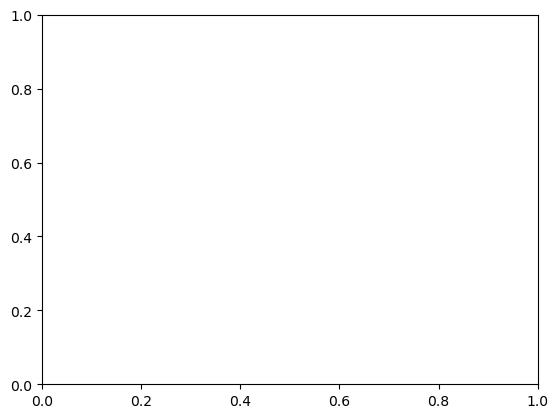

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


r = 0.5   # intrinsic growth rate (per time unit)
K = 200   # carrying capacity

# your code goes here:







# This code is required for the autofeedback- don't delete it!
fighand = plt.gca()

In [3]:
# add tests
runtest(['test_logistic', 'test_logistic_plot'])

The function logistic does not exist.
    Ensure you have named the function properly, bearing in mind that capital
    letters matter. Also ensure that you have used the proper syntax for the
    definition of a function, i.e.
        def logistic(inputs):
            ...
    



What we can observe is that when the population is larger than the carrying capacity, the derivative becomes negative, reducing the population. When its below $K$, the derivative is positive, increasing the population. When it is at $K$, the derivative is zero and the population doesn't change. We can predict all of this from the equation, but this is also the value of doing the modeling: we can check our intuition against the results, and we can change various aspects of the model (i.e. 'play' with it) to see what happens: try changing the carrying capacity or growth rate values, for instance.

## 2. Lotka–Volterra Predator–Prey Model

The **Lotka–Volterra equations** describe a two-species system of prey ($x$) and
predators ($y$):

$$\frac{dx}{dt} = \alpha x - \beta x y$$
$$\frac{dy}{dt} = \delta x y - \gamma y$$

where
- $\alpha$ is the prey birth rate (in absence of predators)
- $\beta$ is the predation rate (rate at which predators eat prey)
- $\delta$ is the predator birth rate per prey eaten
- $\gamma$ is the predator death rate (in absence of prey)

<div style="background:#e8f4f8;border-left:4px solid #2196F3;padding:16px;margin:16px 0;border-radius:4px;width:100%;box-sizing:border-box;overflow-wrap:break-word;">

**Think about what each equation encodes, and attempt to write it down in your own words**

<details style="margin: 1em 0;">
<summary style="cursor:pointer; font-weight:bold; color:#2196F3;">
 Reveal answer
</summary>
<div style="background:#f0f7ff; border-left:4px solid #2196F3; padding:12px 16px; margin-top:8px; border-radius:4px; box-sizing:border-box; overflow-wrap:break-word;">

The first equation says that the rate at which the prey population grows is given by the birth rate times the size of the population (as we saw before for exponential growth), but that rate is reduced (slowed down) by the predators eating the prey. The reason the second term contains $x$ as well as $y$ is that there will be more predation if there are more prey _and_ if there are more predators. If either population goes to zero, then that predation term also goes to zero, as we would expect. 

The second equation says the same thing but in reverse for the predator population. The rate at which that population grows is increased by predation ($\delta xy$), because more food means more predators, and again, the rate at which that happens depends on both the predator _and prey_ populations. The death of predators slows the rate of growth of the predator population ($-\gamma y$).

</div>
</details>

</div>

Once again, we can identify the **Equilibria** for this system. A so-called trivial equilibrium can be found at $(x=0, y=0)$: if both populations are zero, they will remain at zero. 
The non-trivial equilbrium is found at  $(x=\gamma/\delta,\; y=\alpha/\beta)$.
As we'll see, near the non-trivial equilibrium, solutions orbit periodically — the populations oscillate in
an endless cycle.

---

One important thing we are adding in this code is is the ability for our update function `lotka_volterra` to handle the parameters. There are several ways to implement this, but what we do here is add an argument `params` which is a python 'dictionary': each item in a dictionary has a 'key' and a 'value', set up and used like this. 

```python
person = {'name': 'Andrew', 'age': 40, 'height': 185}
print(person['name'])
```

If our update function accepts this parameters argument, then we can get the solver to use it too:

```python
    sol = solve_ivp(lotka_volterra, t_span=(0, 20), y0=y0,
                method='RK45', rtol=1e-8, atol=1e-10, args=(params,)) 
```
(The brackets and comma around `params` in the call here are required because, in principle, we could have several additional arguments)

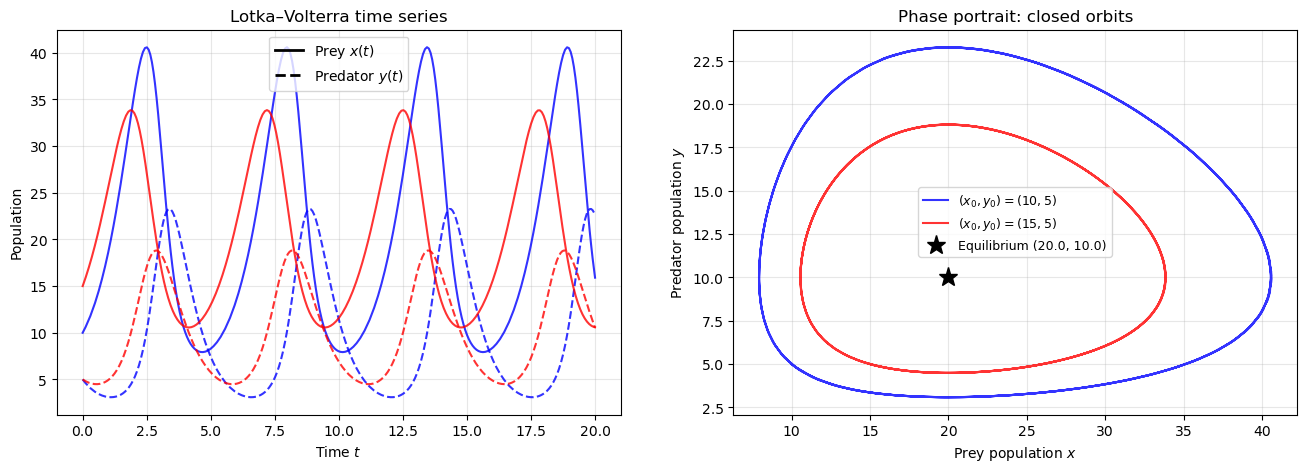

In [4]:
def lotka_volterra(t, state, params):
    '''
    Lotka-Volterra predator-prey equations.

    state = [x, y]  (x = prey population, y = predator population)
    Returns [dx/dt, dy/dt]
    '''
    x, y = state
    dxdt = params['alpha'] * x - params['beta']  * x * y    # prey: born, eaten by predators
    dydt = params['delta'] * x * y - params['gamma'] * y    # predators: born from prey, die naturally
    return [dxdt, dydt]

params = {'alpha': 1.0, 'beta': 0.1, 'delta': 0.075, 'gamma': 1.5}


# Analytical equilibrium
x_star = params['gamma'] / params['delta']
y_star = params['alpha'] / params['beta']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

initial_conditions = [
    [10, 5], [15, 5]
]
colors = ['blue', 'red', 'green', 'purple']

for y0, col in zip(initial_conditions, colors):
    sol = solve_ivp(lotka_volterra, t_span=(0, 20), y0=y0,
                method='RK45', rtol=1e-8, atol=1e-10, args=(params,)) 

    x_sol, y_sol = sol.y[0], sol.y[1]

    # Time series
    axes[0].plot(sol.t, x_sol, color=col, lw=1.5, alpha=0.8)
    axes[0].plot(sol.t, y_sol, color=col, lw=1.5, alpha=0.8, ls='--')

    # Phase portrait
    axes[1].plot(x_sol, y_sol, color=col, lw=1.5, alpha=0.8,
                 label=f'$(x_0, y_0)=({y0[0]},{y0[1]})$')

# Formatting time series
axes[0].plot([], [], 'k-',  lw=2, label='Prey $x(t)$')
axes[0].plot([], [], 'k--', lw=2, label='Predator $y(t)$')
axes[0].set_xlabel('Time $t$'); axes[0].set_ylabel('Population')
axes[0].set_title('Lotka–Volterra time series', fontsize=12)
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

# Formatting phase portrait
axes[1].plot(x_star, y_star, 'k*', ms=14, zorder=10, label=f'Equilibrium ({x_star:.1f}, {y_star:.1f})')
axes[1].set_xlabel('Prey population $x$'); axes[1].set_ylabel('Predator population $y$')
axes[1].set_title('Phase portrait: closed orbits', fontsize=12)
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)


What you should see is that the predator population follows the prey population but with a time-lag. I.E after the amount of available prey has grown sufficiently, the predator population starts to grow. But this increased predator population slows the growth of the prey population, until it begins to decline. This drop in availble prey then precipitates a drop in the predator population and so on. In the phase picture on the right you can see this cyclical relationship in the form of the closed loops.

## 3. Parameter Sensitivity

The qualitative behaviour of the Lotka–Volterra model is controlled by its four parameters.
Understanding how changes to parameters affect the solution is a core part of the
**modelling process**: we must know which parameters matter most, and how sensitive our
predictions are to uncertainty.

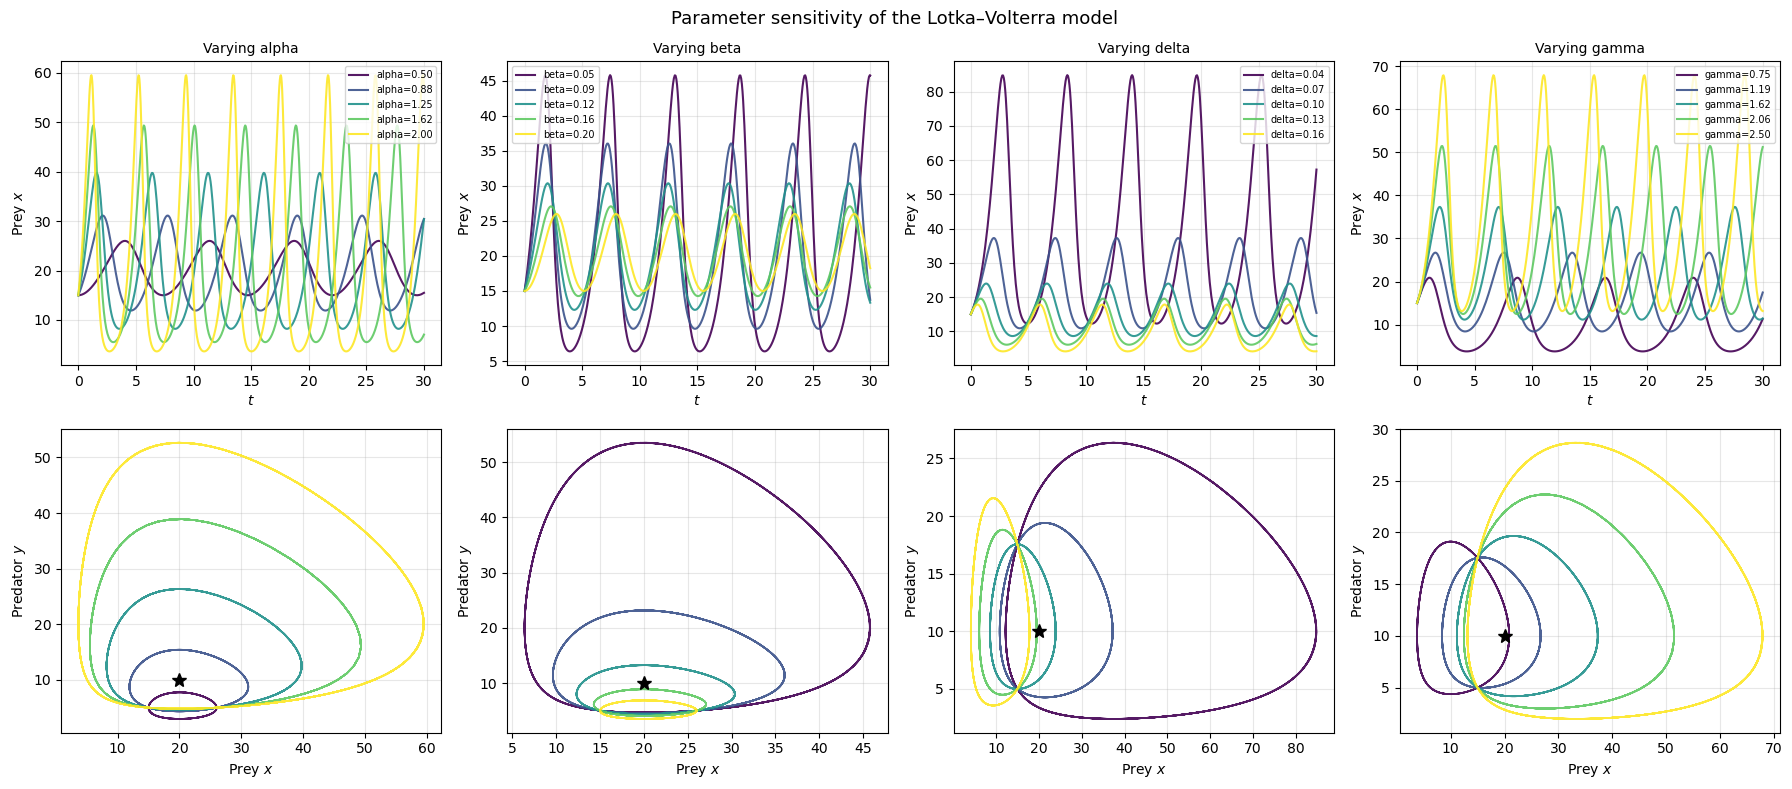

In [5]:
# ── Parameter sensitivity: varying each parameter independently ──────────────

base_params = dict(alpha=1.0, beta=0.1, delta=0.075, gamma=1.5)
y0 = [15.0, 5.0]
T = 30.0

param_ranges = {
    'alpha (prey birth rate)':      ('alpha', np.linspace(0.5, 2.0, 5)),
    'beta (predation rate)':        ('beta',  np.linspace(0.05, 0.2, 5)),
    'delta (predator birth/prey)':  ('delta', np.linspace(0.04, 0.16, 5)),
    'gamma (predator death rate)':  ('gamma', np.linspace(0.75, 2.5, 5)),
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for col_idx, (label, (pname, p_range)) in enumerate(param_ranges.items()):
    cmap = plt.cm.viridis
    for i, pval in enumerate(p_range):
        params = base_params.copy()
        params[pname] = pval
        color = cmap(i / (len(p_range) - 1))

        sol = solve_ivp(lotka_volterra, t_span=(0, 30), y0=y0,
                method='RK45', rtol=1e-8, atol=1e-10, args=(params,))

        # Time series (top row)
        axes[0, col_idx].plot(sol.t, sol.y[0], color=color, lw=1.5, alpha=0.9,
                              label=f'{pname}={pval:.2f}')
        # Phase portrait (bottom row)
        axes[1, col_idx].plot(sol.y[0], sol.y[1], color=color, lw=1.2, alpha=0.9)

    # Equilibrium location
    x_eq = base_params['gamma'] / base_params['delta']
    y_eq = base_params['alpha'] / base_params['beta']
    axes[1, col_idx].plot(x_eq, y_eq, 'k*', ms=10)

    axes[0, col_idx].set_title(f'Varying {pname}', fontsize=10)
    axes[0, col_idx].set_xlabel('$t$'); axes[0, col_idx].set_ylabel('Prey $x$')
    axes[0, col_idx].legend(fontsize=7, ncol=1); axes[0, col_idx].grid(alpha=0.3)

    axes[1, col_idx].set_xlabel('Prey $x$'); axes[1, col_idx].set_ylabel('Predator $y$')
    axes[1, col_idx].grid(alpha=0.3)

plt.suptitle("Parameter sensitivity of the Lotka–Volterra model", fontsize=13)
plt.tight_layout(); plt.show()



<div style="background:#e8f4f8;border-left:4px solid #2196F3;padding:16px;margin:16px 0;border-radius:4px;width:100%;box-sizing:border-box;overflow-wrap:break-word;">

**Look at the diagrams that have been plotted above and try and put into words what varying each parameter does to the behaviour of the system**

You can do this by writing sentences of the form 

> a larger prey birth rate, $\alpha$ leads to ...

or

> increasing the predator death rate, $\gamma$, causes...

But as well as saying what you see, you should try and explain why you see that - does it fit with your intuition, for example?

<details style="margin: 1em 0;">
<summary style="cursor:pointer; font-weight:bold; color:#2196F3;">
 Reveal answer
</summary>
<div style="background:#f0f7ff; border-left:4px solid #2196F3; padding:12px 16px; margin-top:8px; border-radius:4px; box-sizing:border-box; overflow-wrap:break-word;">

ANSWER

### $\alpha$
A larger prey birth rate, $\alpha$ leads to larger/faster oscillations in the populations. Faster oscillations are somewhat obvious: for the prey, $\alpha$ _is_ the rate at which the population regenerates while for the predators, $\alpha$ can be considered as the rate of food production. The fact that the oscillations are larger is somewhat less straightforward, but because there is a lag between the prey being born and the predators eating the prey, it is natural that a higher rate will allow the population to grow larger before predation brings it under control.

### $\beta$
A larger predation rate, $\beta$ reduces the maximum population of prey. That much is fairly straightforward. What might be counterintuitive, though, is that a larger predation rate leads to smaller populations of predators. You might associate 'predation rate' with some sort of 'predator efficiency' and therefore think that maxing $\beta$ would benefit the predator population. But this is not the case and is, in fact, the whole point of these kinds of models. This shows how interlinked the fates of the two populations are – how finely balanced ecosystems can be. If you think about a disease like covid for instance, the most potent forms of the virus are now fairly rare, and the ones that remain are the milder forms. This is because killing off your host very rapidly (having a higher predation rate) is a pretty bad strategy for a virus. 

### $\delta$
$\delta$ encodes the 'predator birth rate per prey eaten'. This could more accurately represent the 'predator efficiency' that we posited in the previous answer. If a predator can convert the energy it gets from eating prey into more predators more efficiently, this should be bad news for the prey, and indeed, that is what we see. An increase in the predator birth rate per prey eaten, $\delta$, leads to a reduction in the maximum prey population. Again, though, because reducing the prey population is actually cutting off the predator's food source, this isn't a straightforward  strategy for domination, and the maximum predator population actually decreases (at first) when we increase $\delta$. However, when $\delta$ becomes sufficiently large, somwehere between $\delta=0.10$ and $0.13$, the maximum predator population begins to grow again. This is because the reduction in prey is less of a problem, because each predator needs less food (that's what $\delta$ encodes). 

### $\gamma$
Increasing the predator death rate, $\gamma$ causes larger populations of prey. This is fairly straightforward: if the predators die off more quickly, more prey will survive. What's surprising is that a larger predator death rate leads to larger predator populations! Again, this counterintuitive finding demonstrates the balance: the predator's dying off more quickly means that the prey population can grow, and the larger prey population can support a larger population of predators. 

</div>
</details>

</div>



## 4. Competitive Exclusion

The construction of the Lotka-Volterra model as we have considered it so far makes it almost<sup>*</sup> impossible for species to die out. Because we have only two species, whose populations are dependent only on each other, what's bad for one tends to be bad for the other and vice versa (as we saw in the 'balance' evident in the most recent set of plots).

A different scenario occurs when two species compete for the same resource: then the Lotka–Volterra _competition_ model
predicts that in many cases only one species can survive. This is called the **competitive exclusion
principle**.

The modified equations are 

$$\frac{dx_1}{dt} = r_1 x_1\!\left(1 - \frac{x_1 + \alpha_{12} x_2}{K_1}\right), \quad
\frac{dx_2}{dt} = r_2 x_2\!\left(1 - \frac{x_2 + \alpha_{21} x_1}{K_2}\right),$$

where $\alpha_{12}$ encodes the competitive effect of species 2 on species 1 and $\alpha_{21}$ the effect of species 1 on species 2. Just like the logistic equation, $r$ represents the birth rate, and $K$ the carrying capacity.

<sup>*</sup> provided the initial populations are non-zero. 

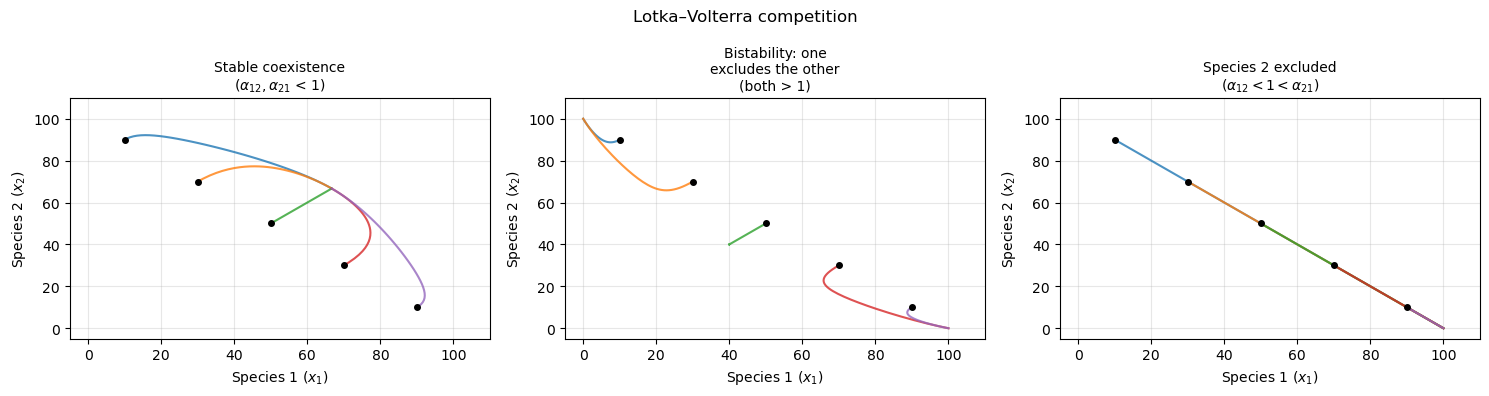

In [6]:
"""
Note that here we are demonstrating a different way to do the parameters in an update function. 
The advantage is that the update function and the call to the solver are much simpler because 
we're not faffing about with dictionaries. The disadvantage is that the list of parameters is 
just a list of numbers:
    params = (1.0, 1.0, 100, 100, a12, a21) 
so if you get them in the wrong order, you're stuffed.
"""
def competition(t, state, r1, r2, K1, K2, a12, a21):
    '''Lotka-Volterra competition between two species.'''
    x1, x2 = state
    dx1 = r1 * x1 * (1 - (x1 + a12 * x2) / K1)
    dx2 = r2 * x2 * (1 - (x2 + a21 * x1) / K2)
    return [dx1, dx2]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
scenarios = [
    # (a12, a21, title)
    (0.5, 0.5, "Stable coexistence\n($\\alpha_{12}, \\alpha_{21}$ < 1)"),
    (1.5, 1.5, "Bistability: one\nexcludes the other\n(both > 1)"),
    (0.5, 1.5, "Species 2 excluded\n($\\alpha_{12}<1 < \\alpha_{21}$)"),
]
for ax, (a12, a21, title) in zip(axes, scenarios):
    for x1_0 in [10, 30, 50, 70, 90]:
        x2_0 = 100 - x1_0
        y0 = [x1_0, x2_0]
        params = (1.0, 1.0, 100, 100, a12, a21)
        sol = solve_ivp(competition, t_span=(0, 30), y0=y0, 
                        method='RK45', rtol=1e-8, atol=1e-10, args=params)
        ax.plot(sol.y[0], sol.y[1], lw=1.5, alpha=0.8)
        ax.plot(x1_0, x2_0, 'ko', ms=4)

    ax.set_xlabel('Species 1 ($x_1$)'); ax.set_ylabel('Species 2 ($x_2$)')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-5, 110); ax.set_ylim(-5, 110)
    ax.grid(alpha=0.3)

plt.suptitle("Lotka–Volterra competition", fontsize=12)
plt.tight_layout(); plt.show()

The fascinating thing shown by these figures is that three genuinely different scenarios arise depending on the relative effects of the populations on each other. If the competitive effect is fairly small ($\alpha<1$) for both populations, then they can peacefully coexist (figure on the left). If however, one species has a much larger effect on the other (figure on the right), then one will go extinct. This is what happened with red and grey squirrels in the UK and Ireland: the indiginous red squirrels didn't have much effect on the larger, invasive greys. But the greys had a huge impact on the reds because they brought diseases against which the reds had no immunity. 

The most interesting behaviour is shown in the middle panel. When the two populations have a large effect on each other, but both are balanced, then the outcome depends on the starting condition: if a population is large to begin with, it will eradicate the other population. If the two populations are equal, then they can live in uneasy equilibrium.

## Exercises

**1. Logistic prey.** Modify the Lotka–Volterra model so that prey grow logistically
(carrying capacity $K$) in the absence of predators:
$$\frac{dx}{dt} = rx\!\left(1-\frac{x}{K}\right) - \beta xy.$$
Call your update function `logprey`: it should take three arguments: `t`, `state=[prey_population, pred_population]` and `params` where `params` is a dictionary containing the parameters as is already set up for you. 

Integrate this modified model and compare its long-term behaviour with the standard model.
Does the conserved quantity still hold?


In [7]:
params = {'r':1.0, 'K':100, 'alpha':1.0, 'beta':0.1, 'delta':0.075, 'gamma':1.5}

# your code goes here:




In [8]:
runtest(['test_logprey'])

The function logprey does not exist.
    Ensure you have named the function properly, bearing in mind that capital
    letters matter. Also ensure that you have used the proper syntax for the
    definition of a function, i.e.
        def logprey(inputs):
            ...
    



## Exercises

**2. Harvesting.** To the logistic, Lotka-Volterra model you just defined, add constant harvesting of the prey at rate $H$: add $-H$ to $dx/dt$. Call your function `LV_harvest`: it should (like all your update functions) take `t`, `state` and `params` as arguments.
Find the critical harvest rate $H_c$ above which the prey (and then predator) go extinct. 

If there's a possibility that one of your populations become extinct, you need to handle that: otherwise the solver will start giving negative populations and/or the whole thing will blow up (mathematically). 

To do that you have to add '[events](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)' to your solver. Events are used to track, well, _events_ that happen during the population modeling, most commonly, when a population goes to zero (becomes extinct). To add an event, you need a function which takes the time, state and parameters (just like your update function), and returns a floating point number which will equal zero when the event is triggered. In the case of extinction, that's dead easy, the function should just return the value of the population. For a predator-prey model, we have two populations, the predators and the prey, but we want to know if either of them goes extinct, so our function looks like 

```python
def extinct(t, state, params):
    prey = state[0]
    pred = state[1]
    return min(prey, pred)
extinct.terminal = True
```
the last line tells the solver to stop solving (terminate) if the event is triggered. You then add this as an argument to the solver 

```python
solve_ivp(...,events=extinct,...)
```

In [9]:
params = {'r': 1.0, 'K': 60, 'beta': 0.1, 'delta': 0.075, 'gamma': 1.5, 'H': 0}


In [10]:
runtest(['test_LV_harvest'])

The function LV_harvest does not exist.
    Ensure you have named the function properly, bearing in mind that capital
    letters matter. Also ensure that you have used the proper syntax for the
    definition of a function, i.e.
        def LV_harvest(inputs):
            ...
    

